In [1]:
#dashboard draft
import voila
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from ipywidgets import interact
import ipywidgets as widgets
from IPython.display import display

#packages for scatterplot and mapping background
import geopandas as gpd
import contextily as ctx

In [2]:
#pull api key
with open('carto_key.txt') as f:
    CARTO_KEY = f.read().strip()
carto_light = f"https://basemaps.cartocdn.com/light_all/{{z}}/{{x}}/{{y}}.png?key={CARTO_KEY}"

district_gdf = gpd.read_file('PoliceDistrictDec2012_20261112.geojson')  # read geojson file

In [3]:
#import + filter data
df = pd.read_csv('Crimes_-_2001_to_Present_20261110.csv')
df['Date'] = df['Date'].str[:10]
#filter top categories
df['crimecol'] = df['Primary Type'].astype("category")
top_categories = df['Primary Type'].value_counts().nlargest(10).index
df.loc[~df['Primary Type'].isin(top_categories), "crimecol"] = "OTHER OFFENSE"
df.loc[df['Primary Type'].isin(top_categories), "crimecol"] = df['Primary Type']
df_lc = df[df["Year"] >= 2023].copy()
df_lc["month"] = df_lc["Date"].str[:2].astype(int)
# drop Nov and Dec of 2026 only
df_lc = df_lc[~((df_lc["Year"] == 2026) & (df_lc["month"] >= 11))]

df['month'] = df['Date'].str[:2]
df['month'] = df['month'].astype("str")
monthdict = {'01':'January','02':'February', '03':'March', '04':'April', '05':'May','06':'June', '07':'July', '08':'August','09':'September', '10':'October','11':'November','12':'December'}
df['month_name'] = df['month'].map(monthdict)




KPI - filtering, think we have to nest this function within the larger entire graph function

In [4]:

#KPI 1:ARREST RATE PERCENTAGE
percentage_arrests = df['Arrest'].mean() * 100
print(f"{percentage_arrests:.2f}%")
#KPI 2: Average crimes per month
year_month = df['Date'].str[6:10] + '-' + df['Date'].str[:2]
year_month = year_month[(year_month >= '2021-01') & (year_month < '2026-11')]

month_counts = year_month.value_counts()

print(f"{month_counts.mean():,.0f}")

#KPI 2: Average crimes per month
year_month = df['Date'].str[6:10] + '-' + df['Date'].str[:2]
year_month = year_month[(year_month >= '2021-01') & (year_month < '2026-11')]

month_counts = year_month.value_counts()

print(f"{month_counts.mean():,.0f}")

15.00%
20,109
20,109


In [5]:
#function for line plot
def monthly_counts(crime, district="All"):
    d = df_lc[df_lc["Primary Type"] == crime]
    if district != "All":
        d = d[d["District"] == district]
    return d.groupby(["Year", "month"]).size().reset_index(name="count")

#function for kpi - should we make the kpis change? - maybe have 2 idk
#KPI Function Definition
ACCENT = '#1f6f8b' # Cyan
MUTED = '#d0d0d0' # Gray

def big_number(ax, value, label, color=ACCENT):
    """Show a large number above a short label in an empty axes."""
    ax.set_axis_off() # Lose all the spines, etc.

    # The value  
    ax.text(0, 0.55, value, fontsize=40, fontweight='bold', color=color,
            transform=ax.transAxes, va='bottom')

    # The label
    ax.text(0, 0.45, label, fontsize=11, color='dimgray',
            transform=ax.transAxes, va='top')

## Notes
1) Create Global Filters - Must apply to all plots
   1) District and Year, - add all filters for these
   2) need to change all plots to query on district as well
2) Make KPIs dependent on filters as well - also import kpis
   1) KPIs should be consistent throughout, having them change isn't optimal
   2) Or the kpi's change with the filters
3) Is the second pie plot the best way to describe/show the other category?
4) Improve stacked bar to show ratio, order by counts
5) Anyway to improve the line chart? was thinking to filter by year, as the current state makes it hard to see the differences between years and even months lowk. But i'm not sure if this solves many problems

Output()

Output()

Output()

Output()

Output()

Output()

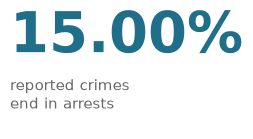

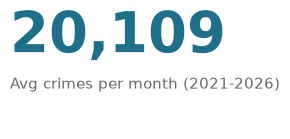

In [6]:
#draft trying to combine pit plots bar and alluvials - can probably reorder/arrange them with other dashboard commadns
#widgets
year_dropdown = widgets.Dropdown(
    options=[2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
    value=2026,
    description='Year:'
)

n_slider = widgets.IntSlider(
    value=8,
    min=1,
    max=14,
    step=1,
    description='Top N:'
)

crimes = sorted(df_lc["Primary Type"].dropna().unique())
district_options = ["All"] + sorted(df_lc["District"].dropna().unique().tolist())

crime_dd = widgets.Dropdown(options=crimes, value="THEFT", description="crime")
district_dd = widgets.Dropdown(options=district_options, value=1, description="district")

'''crime_dropdown = widgets.Dropdown(
    options=['THEFT', 'BATTERY', 'CRIMINAL DAMAGE', 'ASSAULT', 'MOTOR VEHICLE THEFT','OTHER OFFENSE', 'DECEPTIVE PRACTICE', 'BURGLARY', 'ROBBERY', 'WEAPONS VIOLATION'],
    value='THEFT',
    description='Crime Type:'
)

district_dropdown = widgets.Dropdown(
    options=[1,2,3,4,5,6,7,8,9,10,11,12,14,15,16,17,18,19,20,22,24,25,31],
    value=1,
    description='District'
)'''

#plotting function
def pieplotcrimes(year, n):
    pietempdf = df.query("Year == @year")
    counts = pietempdf['Primary Type'].value_counts()

    # get top n crime types from the year, get the rest as separate vars
    top = counts.head(n).copy()
    rest = counts.iloc[n:]

    # create subplots for the two pie charts
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 16))

    # create main pie
    top['Other (combined)'] = rest.sum()
    top.plot.pie(ax=ax1, autopct='%1.2f%%', cmap='RdPu_r')
    ax1.set_title(f'Top {n} types of crime in {year}')
    ax1.set_ylabel('')

    # create pie of other
    rest.plot.pie(ax=ax2, autopct='%1.2f%%', cmap='RdPu_r')
    ax2.set_title(f'Breakdown of "Other" in {year}')
    ax2.set_ylabel('')

    plt.show()

#alluvial and stacked bar
def alluvialplot(year):
    alluvialtempdf = df.query("Year == @year").copy()
    alluvialtempdf['ArrestNum'] = alluvialtempdf['Arrest'].astype(int)
        #alluvialtempf = df[df['Year']==year]

    fig = px.parallel_categories(
        alluvialtempdf,
        dimensions=['crimecol', 'Arrest', 'Domestic'],
        color='ArrestNum',
        color_continuous_scale=['steelblue', 'crimson'],
        width=800, height=450,
    )
    fig.update_traces(line_shape='hspline')
    fig.update_layout(coloraxis_showscale=False)
    display(fig)
def bar_plot(year):
    barplotdf = df.query("Year == @year").copy()
    g = (barplotdf.groupby('Primary Type')['Arrest']
            .agg(total='size', arrests='sum')
            .query('total >= 500')
    )
#g = g.sort_values('total')
    g['rate'] = g['arrests'] / g['total']
    g = g.sort_values('rate')
    g['total'].plot.barh(color='steelblue', figsize=(8, 8), label='Total incidents')
    g['arrests'].plot.barh(color='crimson', label='Arrests')
    plt.xlabel('Number of incidents')
    plt.legend()
    plt.show()

def scatterplot(year, crime, district):
    scatterplot_df = df.query("Year == @year and crimecol == @crime")
    if district == "All":   # whole city: right panel shows every district
        scatterplot_district_df = scatterplot_df
        selected = district_gdf
    else:
        scatterplot_district_df = scatterplot_df[scatterplot_df['District'] == district]
        selected = district_gdf[district_gdf['dist_num'].astype(int) == district]

    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 7))

    district_gdf.boundary.plot(ax=ax0, color='grey', linewidth=0.5)
    selected.boundary.plot(ax=ax0, color='black', linewidth=2)   # show where the district is
    scatterplot_df.plot.scatter(ax=ax0, x='Longitude', y='Latitude', s=0.7, alpha=.08,
                                color='crimson')
    minx, miny, maxx, maxy = district_gdf.total_bounds              # frame the whole city
    ax0.set_xlim(minx - 0.01, maxx + 0.01)
    ax0.set_ylim(miny - 0.01, maxy + 0.01)
    ctx.add_basemap(ax0, crs='EPSG:4326', source=carto_light)
    ax0.set_title(f'Map of {crime} in Chicago in {year}')
    ax0.set_axis_off()

    district_gdf.boundary.plot(ax=ax1, color='grey', linewidth=0.6)
    selected.boundary.plot(ax=ax1, color='black', linewidth=2)
    scatterplot_district_df.plot.scatter(ax=ax1, x='Longitude', y='Latitude', s=1.2, alpha=0.5,
                                             color='crimson')
    minx, miny, maxx, maxy = selected.total_bounds
    ax1.set_xlim(minx - 0.01, maxx + 0.01)
    ax1.set_ylim(miny - 0.01, maxy + 0.01)
    ctx.add_basemap(ax1, crs='EPSG:4326', source=carto_light)
    ax1.set_title(f'Map of {crime} in all districts in {year}' if district == "All" else f'Map of {crime} in District {district} in {year}')
    ax1.set_axis_off()

    plt.tight_layout()
    plt.show()   # only one show, at the end, so both maps render in the same figure
    attribution='© OpenStreetMap contributors © CARTO'

#line plot
month_labels = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

def matrixplot(crime):
    matrixplot = df.query("crimecol == @crime")
    df_wide = matrixplot.pivot_table(index='month_name', columns='Year', values='ID', aggfunc='count')
    df_wide = df_wide.reindex(["January", "February", "March","April","May","June","July","August","September","October","November","December"])
    # need to set the dec and nov of 26 as 0, or like a null, but the 0 is a temp placeholder
    df_wide=df_wide.fillna(0)
    df_wide=df_wide.astype('int')
    display(df_wide.style.background_gradient(cmap='PuRd'))

def plot_line(crime, district):
    counts = monthly_counts(crime, district)
    title = f"{crime.title()} per Month by Year"
    if district != "All":
        title += f" (District {district})"
    fig = px.line(counts, x="month", y="count", color="Year",
                  markers=True, title=title)
    fig.update_xaxes(tickmode="array", tickvals=list(range(1, 13)),
                     ticktext=month_labels, title="Month")
    fig.update_yaxes(title="Number of incidents")
    fig.update_layout(legend_title="Year")
    fig.show()
def matrixplot(crime):
    matrixplot = df.query("crimecol == @crime")
    df_wide = matrixplot.pivot_table(index='month_name', columns='Year', values='ID', aggfunc='count')
    df_wide = df_wide.reindex(["January", "February", "March","April","May","June","July","August","September","October","November","December"])
    # need to set the dec and nov of 26 as 0, or like a null, but the 0 is a temp placeholder
    df_wide=df_wide.fillna(0)
    df_wide=df_wide.astype('int')
    display(df_wide.style.background_gradient(cmap='PuRd'))



#combine widgets and plotting function
#push a section to the left to do all sliders, then have specific interactions for specific plots. should we use 
pie_plot = widgets.interactive_output(pieplotcrimes, {'year': year_dropdown, 'n': n_slider})
display(widgets.HBox([year_dropdown, n_slider, crime_dd, district_dd]), pie_plot)
bar = widgets.interactive_output(bar_plot, {'year': year_dropdown})
display(bar)
alluvial = widgets.interactive_output(alluvialplot, {'year': year_dropdown})
display(alluvial)
scatterplot_display=widgets.interactive_output(scatterplot,{'year': year_dropdown,'crime':crime_dd,'district':district_dd})
display(scatterplot_display)
matrix_display=widgets.interactive_output(matrixplot,{'crime': crime_dd})
display(matrix_display)
line_plot = widgets.interactive_output(plot_line, {"crime": crime_dd, "district": district_dd})
display(line_plot)
#KPI 1
fig, ax = plt.subplots(figsize=(3, 1.5))
big_number(ax, f'{percentage_arrests:.2f}%', 'reported crimes\nend in arrests')
plt.show()
fig, ax = plt.subplots(figsize=(3, 1.5))
big_number(ax, f"{month_counts.mean():,.0f}", "Avg crimes per month (2021-2026)")
plt.show()
# i fear that this may be on a different axis

#kpis - need to have them filter based upon the global filters

